# Tomato Leaf Disease Classification: ML Pipeline Summative

## 1. Introduction
**Problem:** Tomato farmers lose a large part of their harvest to leaf diseases that are often noticed too late. In this project I build an end-to-end ML pipeline that classifies a tomato leaf photo as healthy or as one of several diseases.

**Data:** PlantVillage (Kaggle), tomato leaf images, colour version. I use 4 classes (Early blight, Late blight, Leaf mold, Healthy) with up to 900 images each so that training and retraining stay fast.

**Why images (non-tabular):** the assignment requires non-tabular data, and a CNN can learn visual patterns (spots, colour changes) directly from pixels.

**Notebook plan:** 1) Introduction, 2) Data loading and exploration, 3) Visualizations and interpretations, 4) Preprocessing, 5) Baseline model, 6) Optimized model, 7) Evaluation, 8) Comparison, 9) Prediction and retraining functions, 10) Save and conclusion.

In [1]:
import os, json, random, shutil, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import tensorflow as tf
from tensorflow.keras import layers, regularizers
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_fscore_support

# I fix the seed so that the split, the samples and the training are the same every time I rerun the notebook
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
sns.set_style("whitegrid")
print("TensorFlow:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow: 2.21.0
GPU available: True


## Colab setup (run once per session)
Colab sessions reset, so I keep the **data on the fast local disk** (`/content`) and the **saved models on Google Drive** so I never lose the trained model.

In [2]:
# Mount Google Drive: only the trained models are stored here so they survive a session reset
from google.colab import drive
drive.mount("/content/drive")

DATA_ROOT = "/content/data"                                  # local disk = much faster than reading thousands of images from Drive
MODEL_DIR = "/content/drive/MyDrive/tomato_leaf_project/models"
os.makedirs(DATA_ROOT, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

Mounted at /content/drive


In [3]:
# Read the Kaggle token from Colab Secrets so it never appears in my notebook or GitHub repo
import os
from google.colab import userdata
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

!pip install -q -U kaggle
!kaggle datasets download -d arjuntejaswi/plant-village -p /content/download --unzip

Dataset URL: https://www.kaggle.com/datasets/arjuntejaswi/plant-village
License(s): unknown
100% 329M/329M [00:02<00:00, 129MB/s]



In [4]:
# Folder names differ between PlantVillage versions, so I match on the ending of each folder name
# and copy the 4 chosen classes to data/raw under clean, consistent names.
WANTED = {
    "healthy":      "Tomato_healthy",
    "early_blight": "Tomato_Early_blight",
    "late_blight":  "Tomato_Late_blight",
    "leaf_mold":    "Tomato_Leaf_Mold",
}
os.makedirs(os.path.join(DATA_ROOT, "raw"), exist_ok=True)   # create raw/ first so the final print can never fail

for root, dirs, _ in os.walk("/content/download"):
    for d in dirs:
        name = d.lower()
        if name.startswith("tomato"):
            for key, clean_name in WANTED.items():
                if name.endswith(key):
                    shutil.copytree(os.path.join(root, d), os.path.join(DATA_ROOT, "raw", clean_name), dirs_exist_ok=True)

# Check: I expect exactly 4 folders, each with a few hundred to a few thousand images
for cls in sorted(os.listdir(os.path.join(DATA_ROOT, "raw"))):
    print(cls, len(os.listdir(os.path.join(DATA_ROOT, "raw", cls))))

Tomato_Early_blight 1000
Tomato_Late_blight 1909
Tomato_Leaf_Mold 952
Tomato_healthy 1591


## 2. Data loading and exploration
Paths and settings are in one place, so I can change them without hunting through the notebook.

In [5]:
# Folder layout (data lives on Colab's local disk, see the setup cells above)
RAW_DIR     = f"{DATA_ROOT}/raw"       # the 4 class folders copied from Kaggle
TRAIN_DIR   = f"{DATA_ROOT}/train"
TEST_DIR    = f"{DATA_ROOT}/test"
HOLDOUT_DIR = f"{DATA_ROOT}/holdout"   # images the model never sees; used for demo prediction and retraining upload

IMG_SIZE = (128, 128)             # small enough for fast training, big enough to see leaf spots
IMAGES_PER_CLASS = 900            # cap per class keeps classes balanced; the smallest class has 952 images
HOLDOUT_PER_CLASS = 15
TEST_SPLIT = 0.2                  # 80% train / 20% test of what remains after the holdout
BATCH_SIZE = 32                   # common default that fits easily in GPU memory
VAL_SPLIT = 0.2                   # 20% of the training folder becomes the validation set
AUTOTUNE = tf.data.AUTOTUNE

In [6]:
def split_dataset(raw_dir, train_dir, test_dir, holdout_dir):
    """Split each class folder into train / test / holdout (done per class so every class is represented)."""
    for cls in sorted(os.listdir(raw_dir)):
        cls_path = os.path.join(raw_dir, cls)
        if not os.path.isdir(cls_path):
            continue
        files = sorted(os.listdir(cls_path))
        random.shuffle(files)                      # shuffle first so the split is not biased by file order
        files = files[:IMAGES_PER_CLASS]
        holdout = files[:HOLDOUT_PER_CLASS]
        rest = files[HOLDOUT_PER_CLASS:]
        n_test = int(len(rest) * TEST_SPLIT)
        test, train = rest[:n_test], rest[n_test:]
        for folder, subset in [(train_dir, train), (test_dir, test), (holdout_dir, holdout)]:
            os.makedirs(os.path.join(folder, cls), exist_ok=True)
            for f in subset:
                shutil.copy(os.path.join(cls_path, f), os.path.join(folder, cls, f))
        print(f"{cls}: train={len(train)}, test={len(test)}, holdout={len(holdout)}")

# Only split once: if train/ already exists I do not want to copy and mix files again
if not os.path.exists(TRAIN_DIR):
    split_dataset(RAW_DIR, TRAIN_DIR, TEST_DIR, HOLDOUT_DIR)
else:
    print("Split already done, skipping.")

Tomato_Early_blight: train=708, test=177, holdout=15
Tomato_Late_blight: train=708, test=177, holdout=15
Tomato_Leaf_Mold: train=708, test=177, holdout=15
Tomato_healthy: train=708, test=177, holdout=15


In [7]:
# Class names come from the folder names, so the notebook adapts if I change the classes
CLASSES = sorted(os.listdir(TRAIN_DIR))
print("Classes:", CLASSES)

def count_images(folder):
    return {cls: len(os.listdir(os.path.join(folder, cls))) for cls in CLASSES}

counts_df = pd.DataFrame({"train": count_images(TRAIN_DIR), "test": count_images(TEST_DIR)})
counts_df["total"] = counts_df["train"] + counts_df["test"]
counts_df

Classes: ['Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_healthy']


,train,test,total
Tomato_Early_blight,708,177,885
Tomato_Late_blight,708,177,885
Tomato_Leaf_Mold,708,177,885
Tomato_healthy,708,177,885


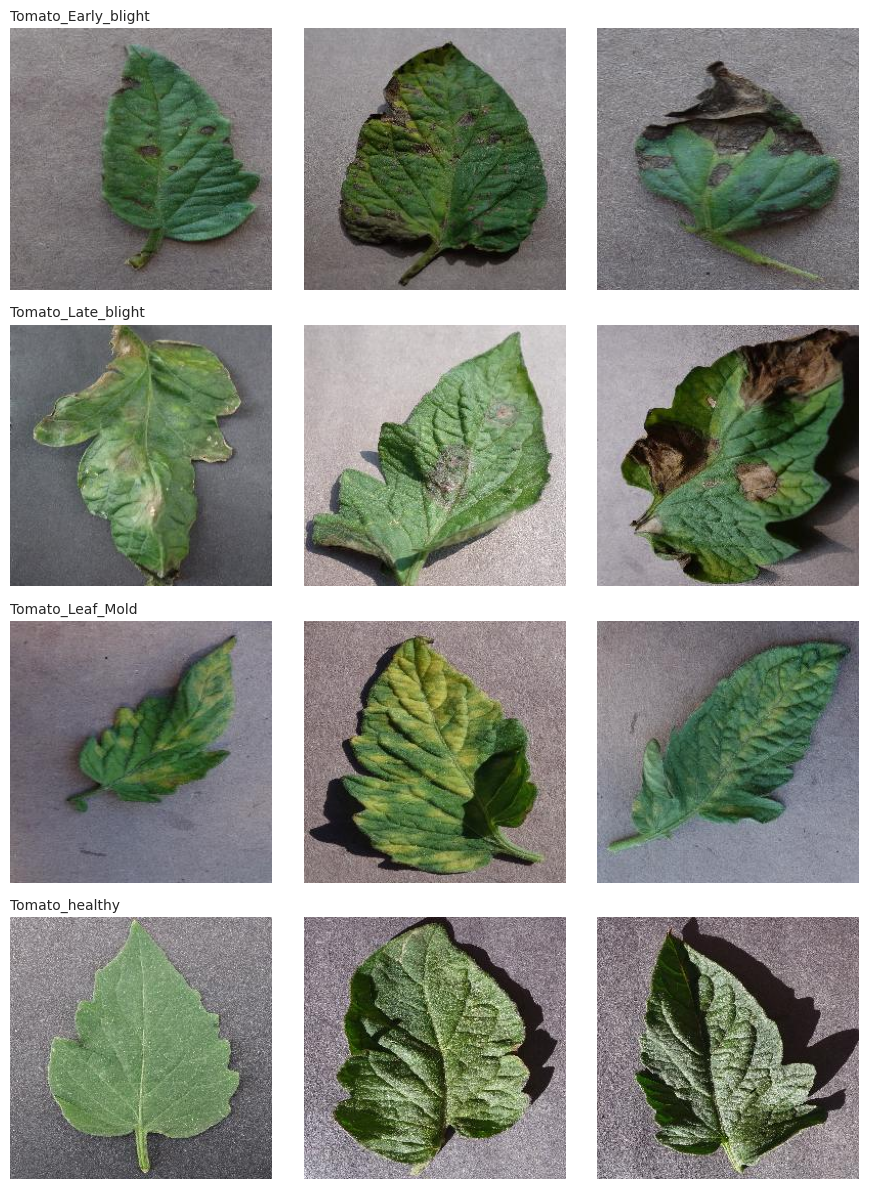

In [8]:
# Looking at real images first: I want to see what the model will have to tell apart
fig, axes = plt.subplots(len(CLASSES), 3, figsize=(9, 3 * len(CLASSES)))
for i, cls in enumerate(CLASSES):
    cls_path = os.path.join(TRAIN_DIR, cls)
    for j, fname in enumerate(random.sample(os.listdir(cls_path), 3)):
        axes[i, j].imshow(Image.open(os.path.join(cls_path, fname)))
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(cls, fontsize=10, loc="left")
plt.tight_layout()
plt.show()

## 3. Visualizations and interpretations
I extract simple numeric features from a sample of training images (up to 100 per class, resized for speed) and use them to answer: *is the data balanced, and do the classes look different in ways a model can use?*

In [9]:
# Extract simple image features: mean R, G, B and overall brightness per image
rows = []
for cls in CLASSES:
    cls_path = os.path.join(TRAIN_DIR, cls)
    sample = random.sample(os.listdir(cls_path), min(100, len(os.listdir(cls_path))))
    for fname in sample:
        img = Image.open(os.path.join(cls_path, fname)).convert("RGB").resize(IMG_SIZE)
        arr = np.array(img, dtype=np.float32)
        gray = np.array(img.convert("L"), dtype=np.float32)   # grayscale version for brightness and texture
        rows.append({
            "class": cls,
            "mean_R": arr[:, :, 0].mean(),
            "mean_G": arr[:, :, 1].mean(),
            "mean_B": arr[:, :, 2].mean(),
            "brightness": gray.mean(),
            "texture": gray.std(),     # spread of pixel intensities: spots and lesions raise local contrast
        })
features_df = pd.DataFrame(rows)
features_df.groupby("class").mean().round(1)

,mean_R,mean_G,mean_B,brightness,texture
class,,,,,
Tomato_Early_blight,109.000000,113.500000,101.800003,110.800003,45.700001
Tomato_Late_blight,114.199997,114.300003,102.199997,112.900002,38.900002
Tomato_Leaf_Mold,113.300003,117.900002,115.500000,116.199997,35.400002
Tomato_healthy,114.000000,119.000000,111.000000,116.599998,29.900000


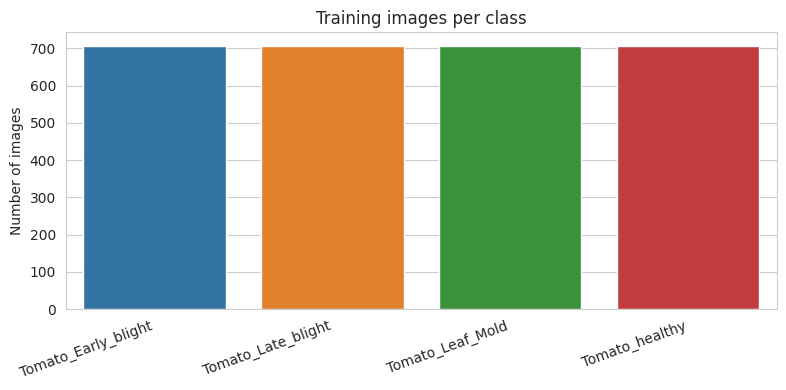

In [10]:
# Visualization 1: class distribution (is the dataset balanced?)
plt.figure(figsize=(8, 4))
sns.barplot(x=counts_df.index, y=counts_df["train"], hue=counts_df.index, legend=False)
plt.title("Training images per class")
plt.ylabel("Number of images")
plt.xlabel("")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

**Interpretation 1: class balance.**
The chart shows that all four classes (Early blight, Late blight, Leaf mold and Healthy) have almost the same number of training images, about 708 each. The original data was not balanced (about 1000, 1909, 952 and 1591 images per class), and I capped every class at 900 images before splitting, which is what made them equal. It matters for two reasons. First, the model sees each class equally often during training, so it has no reason to favour a class just because it is more common. Second, plain accuracy is a fair metric here, since a model that always guessed one class would score only about 25%. That is the baseline to beat. Because the classes are balanced, I do not need class weights or oversampling. The trade-off is that capping discards some images from the larger classes, which I accept to keep training and retraining fast.

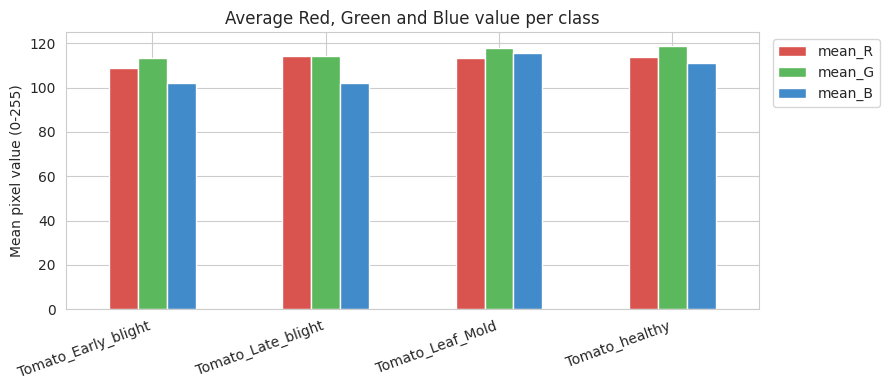

In [11]:
# Visualization 2: average colour channels per class
channel_means = features_df.groupby("class")[["mean_R", "mean_G", "mean_B"]].mean()
channel_means.plot(kind="bar", figsize=(9, 4), color=["#d9534f", "#5cb85c", "#428bca"])
plt.title("Average Red, Green and Blue value per class")
plt.ylabel("Mean pixel value (0-255)")
plt.xlabel("")
plt.xticks(rotation=20, ha="right")
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1))   # legend outside so it does not hide the bars
plt.tight_layout()
plt.show()

**Interpretation 2: colour.**
The chart shows that the average colour differs only slightly between classes, with all channels between about 100 and 120. Green is the strongest channel in every class, as expected for leaves. A few small differences stand out. Leaf mold (about 115) and healthy (about 111) have a higher blue value than Early blight (about 102) and Late blight (about 102), and Leaf mold's blue is close to its green value (about 117), which suggests a paler or greyer leaf surface. Early blight and Late blight have the lowest blue values, which is consistent with their darker lesions. These two diseases also have almost the same average colour, with green and blue within about 1 point of each other and red about 5 points apart. This tells me that simple average colour is not enough to separate the classes, and Early blight and Late blight would be confused the most if I relied on colour alone. The model needs to learn local patterns such as the shape, size and edges of the spots, which is what a CNN is good at, and it is why I use one instead of a colour-based classifier. I expect Early blight and Late blight to be the most confused pair, and I will check this in the confusion matrix.

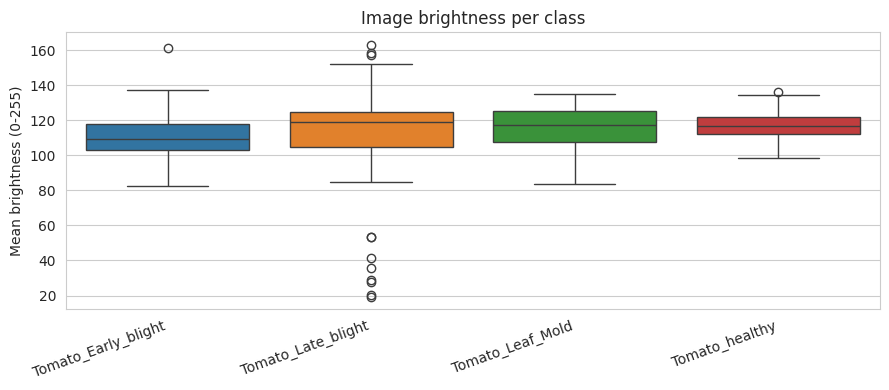

,brightness
class,
Tomato_Early_blight,109.400002
Tomato_Late_blight,119.099998
Tomato_Leaf_Mold,117.300003
Tomato_healthy,116.900002


In [12]:
# Visualization 3: brightness distribution per class (checks whether lighting could mislead the model)
plt.figure(figsize=(9, 4))
sns.boxplot(data=features_df, x="class", y="brightness", hue="class", legend=False)
plt.title("Image brightness per class")
plt.ylabel("Mean brightness (0-255)")
plt.xlabel("")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# Numbers for the interpretation: median brightness per class
features_df.groupby("class")["brightness"].median().round(1)

**Interpretation 3: brightness and lighting.**
The boxplot shows that the median brightness is similar across all four classes, between about 109 and 119. This is useful because the model cannot classify by lighting alone and has to rely on the leaf itself. Early blight is slightly darker, which agrees with the colour chart and its dark spots. Healthy leaves have the narrowest spread, so those photos were taken under very consistent conditions, while the diseased classes vary more. Late blight also has outliers at both ends, with some very dark images (below 60) and some very bright ones (above 150). This is a risk, because a model could learn lighting quirks instead of disease patterns, and it may struggle with real farm photos taken in sun or shade. To reduce this I add brightness and flip augmentation in preprocessing, so the model sees the same leaf under different lighting. These statistics come from a sample of 100 images per class, so they approximate the full training set.

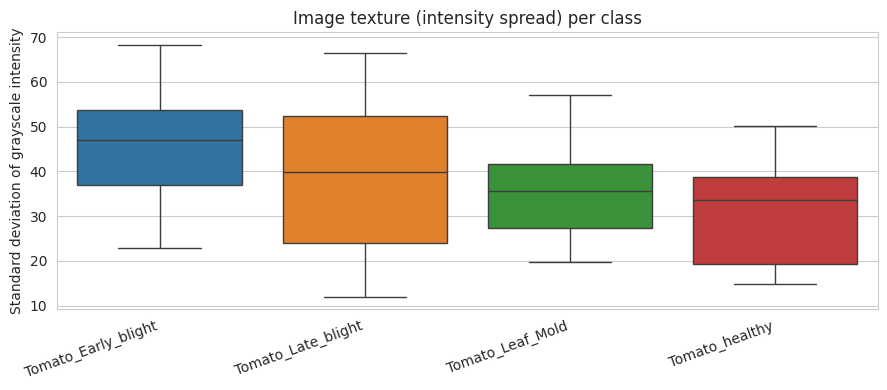

,texture
class,
Tomato_Early_blight,47.000000
Tomato_Late_blight,39.799999
Tomato_Leaf_Mold,35.599998
Tomato_healthy,33.700001


In [13]:
# Visualization 4: texture (how much the pixel intensity varies inside an image) per class
plt.figure(figsize=(9, 4))
sns.boxplot(data=features_df, x="class", y="texture", hue="class", legend=False)
plt.title("Image texture (intensity spread) per class")
plt.ylabel("Standard deviation of grayscale intensity")
plt.xlabel("")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# Numbers for the interpretation: median texture per class
features_df.groupby("class")["texture"].median().round(1)

### **Interpretation 4: texture**

* **Texture Profiles:**
  * **Tomato_Early_blight** has the highest median texture (**47.0**), reflecting the high local contrast created by its defined, dark concentric rings and target-like lesions.
  * **Tomato_healthy** has the lowest median texture (**33.7**), consistent with a smooth, even leaf surface without lesions.

* **Visual Patterns & Hypotheses:**
  * The data supports the idea that lesions change the textural signature. Healthy leaves are the smoothest (median **33.7**) and Leaf Mold is close behind (**35.6**), while Early Blight (**47.0**) and Late Blight (**39.8**) have higher texture, which fits the dark spots, lesions and dry borders these diseases create.

* **Spread & Reliability:**
  * The interquartile range (IQR) within each class is moderately wide, showing some overlap. This spread indicates that texture alone is an unreliable single feature for classification, as a particularly spotted healthy leaf or a mild blight infection could easily be miscategorized.

* **Implications for the CNN:**
  * While simple color, brightness, or hand-crafted texture statistics on their own are not robust enough to separate these classes, they reveal a rich structural signal. A Convolutional Neural Network (CNN) is uniquely suited here because it does not look at these features in isolation; it extracts hierarchical, spatially-aware combinations of local edges, boundaries, and spot patterns to reliably distinguish healthy tissues from diseased ones.

**What story does the data tell?**
The dataset is balanced after capping, so accuracy is a fair metric. The classes are very similar in average colour and brightness, so simple summary features cannot separate them. The differences that exist (Early blight is darker, Leaf mold is paler and greyer, Late blight has extreme lighting outliers) point to local patterns such as spots and texture rather than overall colour. This is why I use a CNN that learns shapes and textures directly from pixels, why I add augmentation to handle lighting variety, and why I expect the most similar classes to be confused most often.

## 4. Preprocessing
Raw leaf photos cannot go straight into a CNN. These are the steps I apply and why:

| Step | What | Why |
|---|---|---|
| 1. Resize | every image to 128x128 | the network needs one fixed input size, and small images train fast |
| 2. RGB | force 3 colour channels | a few files could be grayscale or RGBA, which would break the input shape |
| 3. Scale | pixel values 0-255 to 0-1 (done inside the model) | small, similar-sized inputs make gradient descent more stable |
| 4. Split | train / validation / test | validation is for tuning and early stopping, test is only for the final honest score |
| 5. Augment | random flips, rotation, zoom, brightness (training data only) | gives the model more variety and handles the lighting spread seen in Visualization 3 |
| 6. Prefetch | load the next batch while the GPU trains | removes waiting time |

I keep the scaling **inside the model** so the API and the retraining code cannot forget it, since they reuse the same model file.

In [14]:
def load_train_val(train_dir, img_size=IMG_SIZE, batch_size=BATCH_SIZE, val_split=VAL_SPLIT, seed=SEED):
    """Read images from class sub-folders (folder name = label) and return train and validation datasets."""
    # Both calls need the SAME seed and split, otherwise training and validation images could overlap
    common = dict(validation_split=val_split, seed=seed, image_size=img_size,
                  batch_size=batch_size, label_mode="categorical")
    train_ds = tf.keras.utils.image_dataset_from_directory(train_dir, subset="training", **common)
    val_ds = tf.keras.utils.image_dataset_from_directory(train_dir, subset="validation", **common)
    return train_ds, val_ds

def load_test(test_dir, img_size=IMG_SIZE, batch_size=BATCH_SIZE):
    """Test data is NOT shuffled so predictions line up with labels in the confusion matrix."""
    return tf.keras.utils.image_dataset_from_directory(
        test_dir, image_size=img_size, batch_size=batch_size,
        label_mode="categorical", shuffle=False)

def preprocess_image(image_path, img_size=IMG_SIZE):
    """Prepare ONE image for prediction exactly like the training images (used later by the API)."""
    img = Image.open(image_path).convert("RGB")          # force 3 channels
    img = img.resize(img_size, Image.BILINEAR)           # bilinear = same method TensorFlow used in training
    arr = np.array(img, dtype=np.float32)                # still 0-255, the model rescales itself
    return np.expand_dims(arr, axis=0)                   # add batch dimension: (1, 128, 128, 3)

In [15]:
# Augmentation: random changes so the model sees "new" versions of each leaf every epoch.
# A leaf photographed upside down, rotated, closer or in different light is still the same disease.
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),                               # up to about 36 degrees
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.2, value_range=(0, 255)),       # answers the lighting spread from Visualization 3
], name="augmentation")

def prepare(ds, augment=False):
    """Apply augmentation only to training data (never to validation or test) and prefetch for speed."""
    if augment:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                    num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

In [16]:
# Build the datasets
train_ds, val_ds = load_train_val(TRAIN_DIR)
test_ds = load_test(TEST_DIR)

# Get class names BEFORE prepare(), because map() removes the class_names attribute
class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Class order used by the model:", class_names)

# Save the class order: the API must use the SAME order to turn a prediction number into a disease name
with open(os.path.join(MODEL_DIR, "class_names.json"), "w") as f:
    json.dump(class_names, f)

train_ds = prepare(train_ds, augment=True)
val_ds = prepare(val_ds)
test_ds = prepare(test_ds)

Found 2832 files belonging to 4 classes.
Using 2266 files for training.
Found 2832 files belonging to 4 classes.
Using 566 files for validation.
Found 708 files belonging to 4 classes.
Class order used by the model: ['Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_healthy']


In [17]:
# Sanity check: shapes and pixel range should be what the model expects
x_batch, y_batch = next(iter(train_ds))
print("Images:", x_batch.shape, "| Labels:", y_batch.shape)
print("Pixel range:", float(tf.reduce_min(x_batch)), "to", float(tf.reduce_max(x_batch)), "(model will rescale to 0-1)")

Images: (32, 128, 128, 3) | Labels: (32, 4)
Pixel range: 0.0 to 255.0 (model will rescale to 0-1)


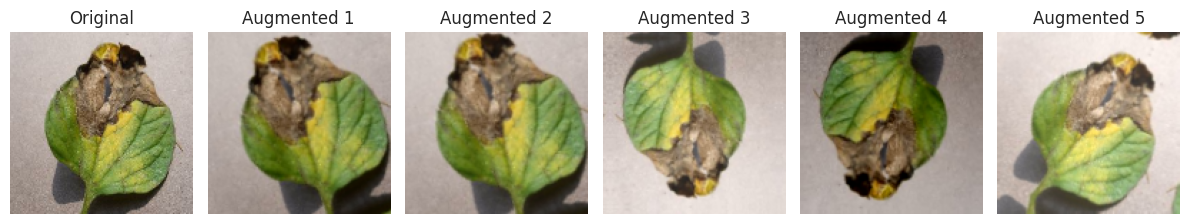

In [18]:
# Show what augmentation does: the SAME leaf, augmented 5 times
sample_img = next(iter(val_ds))[0][0]
plt.figure(figsize=(12, 3))
plt.subplot(1, 6, 1)
plt.imshow(sample_img.numpy().astype("uint8"))
plt.title("Original")
plt.axis("off")
for i in range(5):
    aug = data_augmentation(tf.expand_dims(sample_img, 0), training=True)
    plt.subplot(1, 6, i + 2)
    plt.imshow(aug[0].numpy().astype("uint8"))
    plt.title(f"Augmented {i+1}")
    plt.axis("off")
plt.tight_layout()
plt.show()

**Why this preprocessing fits my data.** The augmented images show the same leaf with different flips, angles, zoom and brightness. From the exploration I know the classes differ only slightly in average colour and that Late blight has very dark and very bright outliers, so the model cannot rely on colour or lighting alone. Augmentation forces it to learn the shape and texture of the spots instead. I apply it to the training data only, so the validation and test scores measure performance on real, unmodified images.

## Helper functions for training and evaluation
Defined once and reused for every model, so all models are scored in exactly the same way.

In [19]:
def plot_history(history, title):
    """Training vs validation accuracy and loss: the gap between them shows overfitting."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(history.history["accuracy"], label="train")
    axes[0].plot(history.history["val_accuracy"], label="validation")
    axes[0].set_title(f"{title}: accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()
    axes[1].plot(history.history["loss"], label="train")
    axes[1].plot(history.history["val_loss"], label="validation")
    axes[1].set_title(f"{title}: loss")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

def get_predictions(model, ds):
    """Return true and predicted class numbers for a dataset that is NOT shuffled."""
    y_true = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in ds])
    y_pred = np.argmax(model.predict(ds, verbose=0), axis=1)
    return y_true, y_pred

def evaluate_model(model, ds, name):
    """Compute loss, accuracy, precision, recall and F1 (weighted over classes) on a dataset."""
    loss, acc = model.evaluate(ds, verbose=0)
    y_true, y_pred = get_predictions(model, ds)
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    return {"model": name, "loss": loss, "accuracy": acc, "precision": precision, "recall": recall, "f1": f1}

def plot_confusion(y_true, y_pred, title):
    """Confusion matrix: rows = true class, columns = predicted class."""
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(title)
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

def show_misclassified(model, ds, n=6):
    """Display a few test images the model got wrong, to understand its mistakes."""
    shown = 0
    plt.figure(figsize=(14, 3))
    for images, labels in ds:
        preds = np.argmax(model.predict(images, verbose=0), axis=1)
        true = np.argmax(labels.numpy(), axis=1)
        for i in np.where(preds != true)[0]:
            if shown >= n:
                break
            plt.subplot(1, n, shown + 1)
            plt.imshow(images[i].numpy().astype("uint8"))
            plt.title(f"True: {class_names[true[i]].replace('Tomato_', '')}\nPred: {class_names[preds[i]].replace('Tomato_', '')}", fontsize=8)
            plt.axis("off")
            shown += 1
        if shown >= n:
            break
    if shown == 0:
        print("No misclassified images in the test set.")
    plt.tight_layout()
    plt.show()

## 5. Baseline model (no optimization)
A deliberately simple CNN with no regularization, no early stopping and no tuning. It gives me a reference point, so later I can show how much each optimization actually helps.

In [20]:
def build_baseline(num_classes):
    """Small plain CNN: two conv blocks and one dense layer. Default Adam, nothing tuned."""
    model = tf.keras.Sequential([
        layers.Input(shape=IMG_SIZE + (3,)),
        layers.Rescaling(1.0 / 255),                      # scale pixels to 0-1 inside the model
        layers.Conv2D(16, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(32, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(num_classes, activation="softmax"),  # one probability per class
    ], name="baseline_cnn")
    model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    return model

baseline_model = build_baseline(NUM_CLASSES)
baseline_model.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 28800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,843,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,848,612 (7.05 MB)

 Trainable params: 1,848,612 (7.05 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
71/71 - 27s - 381ms/step - accuracy: 0.4563 - loss: 1.2709 - val_accuracy: 0.4912 - val_loss: 1.0219
Epoch 2/10
71/71 - 8s - 119ms/step - accuracy: 0.6130 - loss: 0.9725 - val_accuracy: 0.5265 - val_loss: 1.0458
Epoch 3/10
71/71 - 12s - 163ms/step - accuracy: 0.6717 - loss: 0.7934 - val_accuracy: 0.7509 - val_loss: 0.5840
Epoch 4/10
71/71 - 12s - 164ms/step - accuracy: 0.7648 - loss: 0.6196 - val_accuracy: 0.7933 - val_loss: 0.4928
Epoch 5/10
71/71 - 10s - 142ms/step - accuracy: 0.7935 - loss: 0.5431 - val_accuracy: 0.8057 - val_loss: 0.4726
Epoch 6/10
71/71 - 9s - 129ms/step - accuracy: 0.8160 - loss: 0.4761 - val_accuracy: 0.7951 - val_loss: 0.5006
Epoch 7/10
71/71 - 11s - 153ms/step - accuracy: 0.8460 - loss: 0.4161 - val_accuracy: 0.8940 - val_loss: 0.2886
Epoch 8/10
71/71 - 10s - 145ms/step - accuracy: 0.8469 - loss: 0.3978 - val_accuracy: 0.8887 - val_loss: 0.3113
Epoch 9/10
71/71 - 8s - 119ms/step - accuracy: 0.8751 - loss: 0.3483 - val_accuracy: 0.8975 - val_loss: 0.

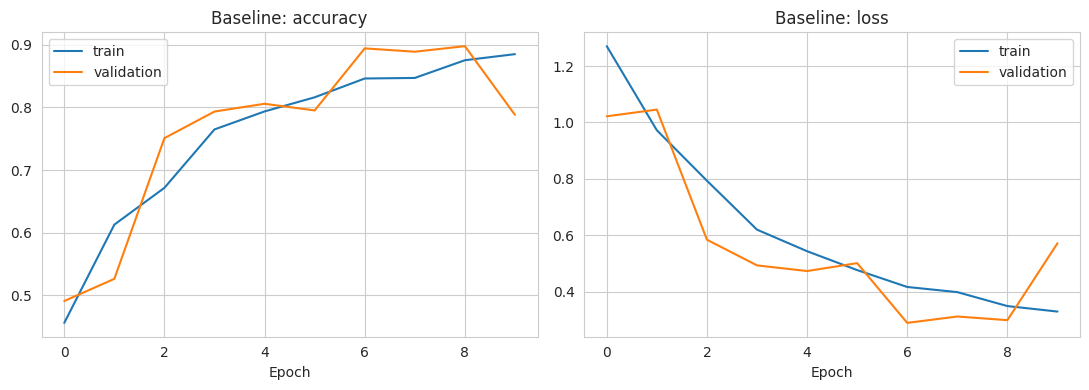

In [21]:
# Fixed 10 epochs, no callbacks: this is the "vanilla" setup
baseline_history = baseline_model.fit(train_ds, validation_data=val_ds, epochs=10, verbose=2)
plot_history(baseline_history, "Baseline")

## 6. Optimized model
My custom CNN with these optimization techniques, each with a reason:

| Technique | Why |
|---|---|
| **He initialization** | suits ReLU layers, so the plain CNN starts learning quickly without batch normalization |
| **L2 regularization** | penalizes large weights to reduce overfitting |
| **Dropout** | randomly switches off neurons so the model cannot rely on a few of them |
| **Adam optimizer with tuned learning rate** | adaptive optimizer, and the learning rate is the most important hyperparameter |
| **Early stopping** | stops when validation loss stops improving and restores the best weights |
| **ReduceLROnPlateau** | lowers the learning rate when progress stalls, for finer final adjustments |
| **Hyperparameter search** | tries learning rate and dropout combinations instead of guessing |
| **Data augmentation** | already applied in preprocessing |

*Note: in earlier runs I also tried batch normalization. Validation accuracy jumped around and validation loss spiked above 4 even though training accuracy was fine, so I removed it.*

In [22]:
def build_optimized(num_classes, dropout=0.3, l2=1e-4, lr=1e-3):
    """Deeper CNN: 4 conv blocks, He initialization, L2 regularization, Dropout and a configurable Adam learning rate."""
    reg = regularizers.l2(l2)

    def conv_block(filters):
        # Conv (He init suits ReLU) -> MaxPool: halves the image size each time (128 -> 64 -> 32 -> 16 -> 8)
        return [
            layers.Conv2D(filters, 3, padding="same", activation="relu",
                          kernel_initializer="he_normal", kernel_regularizer=reg),
            layers.MaxPooling2D(),
        ]

    model = tf.keras.Sequential(
        [layers.Input(shape=IMG_SIZE + (3,)), layers.Rescaling(1.0 / 255)]
        + conv_block(32) + conv_block(64) + conv_block(128) + conv_block(128)
        + [
            layers.Flatten(),                              # keeps the spatial layout of spots, like the stable baseline
            layers.Dropout(dropout),
            layers.Dense(128, activation="relu", kernel_initializer="he_normal", kernel_regularizer=reg),
            layers.Dropout(dropout),
            layers.Dense(num_classes, activation="softmax"),
        ],
        name="optimized_cnn",
    )
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    return model

In [23]:
# Hyperparameter search: learning rate x dropout, compared on VALIDATION data
# (the test set stays untouched, otherwise I would be tuning on the data I use for the final score).
# Score = average validation accuracy of the LAST 3 epochs, so one lucky spike cannot decide the winner.
search_results = []
for lr, dropout in itertools.product([1e-3, 3e-4], [0.3, 0.5]):
    tf.keras.backend.clear_session()                       # fresh start for each trial
    trial = build_optimized(NUM_CLASSES, dropout=dropout, lr=lr)
    h = trial.fit(train_ds, validation_data=val_ds, epochs=10, verbose=0)
    score = float(np.mean(h.history["val_accuracy"][-3:]))
    search_results.append({"learning_rate": lr, "dropout": dropout, "val_acc_last3_mean": round(score, 4)})
    print(f"lr={lr}, dropout={dropout} -> val accuracy (last 3 epochs avg) {score:.4f}")

search_df = pd.DataFrame(search_results).sort_values("val_acc_last3_mean", ascending=False).reset_index(drop=True)
search_df

lr=0.001, dropout=0.3 -> val accuracy (last 3 epochs avg) 0.8174
lr=0.001, dropout=0.5 -> val accuracy (last 3 epochs avg) 0.8457
lr=0.0003, dropout=0.3 -> val accuracy (last 3 epochs avg) 0.7509
lr=0.0003, dropout=0.5 -> val accuracy (last 3 epochs avg) 0.6696


,learning_rate,dropout,val_acc_last3_mean
0,0.0010,0.5,0.8457
1,0.0010,0.3,0.8174
2,0.0003,0.3,0.7509
3,0.0003,0.5,0.6696


Best settings -> learning rate: 0.001 | dropout: 0.5
Epoch 1/40
71/71 - 20s - 278ms/step - accuracy: 0.3155 - loss: 1.5181 - val_accuracy: 0.5406 - val_loss: 1.2314 - learning_rate: 0.0010
Epoch 2/40
71/71 - 10s - 144ms/step - accuracy: 0.5455 - loss: 1.1153 - val_accuracy: 0.6855 - val_loss: 0.8225 - learning_rate: 0.0010
Epoch 3/40
71/71 - 8s - 117ms/step - accuracy: 0.6567 - loss: 0.8890 - val_accuracy: 0.7562 - val_loss: 0.6582 - learning_rate: 0.0010
Epoch 4/40
71/71 - 10s - 147ms/step - accuracy: 0.6999 - loss: 0.8269 - val_accuracy: 0.7527 - val_loss: 0.6753 - learning_rate: 0.0010
Epoch 5/40
71/71 - 10s - 143ms/step - accuracy: 0.7454 - loss: 0.7049 - val_accuracy: 0.6484 - val_loss: 0.9001 - learning_rate: 0.0010
Epoch 6/40

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
71/71 - 8s - 115ms/step - accuracy: 0.7754 - loss: 0.6550 - val_accuracy: 0.7350 - val_loss: 0.7358 - learning_rate: 0.0010
Epoch 7/40
71/71 - 10s - 144ms/step - accuracy: 0.8332 -

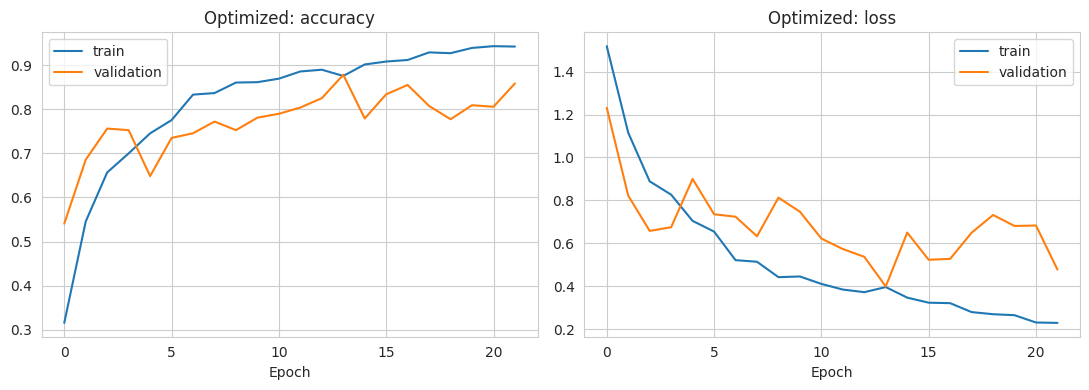

In [24]:
# Take the best combination from the search
best = search_df.iloc[0]
BEST_LR, BEST_DROPOUT = float(best["learning_rate"]), float(best["dropout"])
print("Best settings -> learning rate:", BEST_LR, "| dropout:", BEST_DROPOUT)

tf.keras.backend.clear_session()
optimized_model = build_optimized(NUM_CLASSES, dropout=BEST_DROPOUT, lr=BEST_LR)

callbacks = [
    # stop if validation loss does not improve for 8 epochs, and go back to the best weights
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    # halve the learning rate if validation loss is stuck for 3 epochs
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1),
    # keep the best model on Drive in case Colab disconnects
    tf.keras.callbacks.ModelCheckpoint(os.path.join(MODEL_DIR, "tomato_cnn_best.keras"),
                                       monitor="val_loss", save_best_only=True),
]

# Up to 40 epochs, but early stopping will usually end it sooner
optimized_history = optimized_model.fit(train_ds, validation_data=val_ds, epochs=40, callbacks=callbacks, verbose=2)
plot_history(optimized_history, "Optimized")

## 7. Evaluation
Both models are scored on the **test set**, which neither model saw during training or tuning. Metrics: accuracy, loss, precision, recall and F1. Precision, recall and F1 are weighted averages over the classes.

In [25]:
baseline_scores = evaluate_model(baseline_model, test_ds, "Baseline CNN")
optimized_scores = evaluate_model(optimized_model, test_ds, "Optimized CNN")

results_df = pd.DataFrame([baseline_scores, optimized_scores]).set_index("model").round(4)
results_df

,loss,accuracy,precision,recall,f1
model,,,,,
Baseline CNN,0.5671,0.8079,0.8425,0.8079,0.8031
Optimized CNN,0.3879,0.8884,0.8953,0.8884,0.8869


                     precision    recall  f1-score   support

Tomato_Early_blight      0.860     0.870     0.865       177
 Tomato_Late_blight      0.978     0.763     0.857       177
   Tomato_Leaf_Mold      0.896     0.921     0.908       177
     Tomato_healthy      0.847     1.000     0.917       177

           accuracy                          0.888       708
          macro avg      0.895     0.888     0.887       708
       weighted avg      0.895     0.888     0.887       708



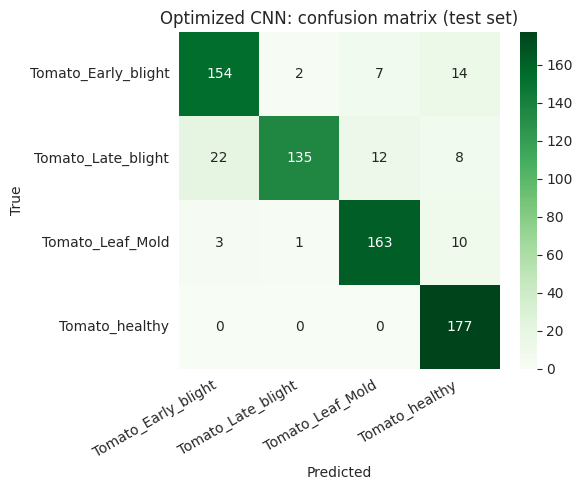

In [26]:
# Per-class results for the optimized model: shows WHICH classes are hard, not just the overall score
y_true, y_pred = get_predictions(optimized_model, test_ds)
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
plot_confusion(y_true, y_pred, "Optimized CNN: confusion matrix (test set)")

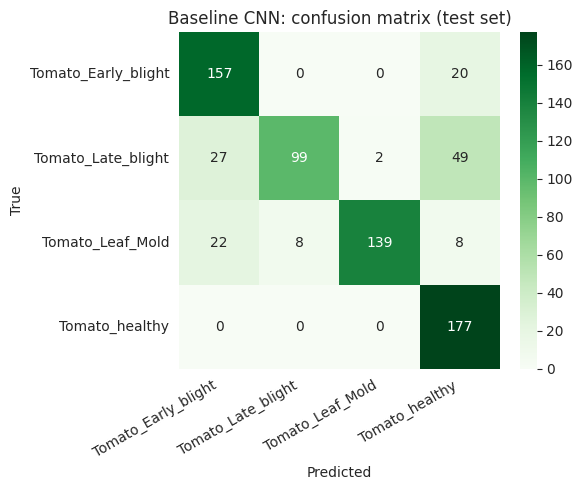

In [27]:
# The same confusion matrix for the baseline, to compare the kinds of mistakes
yb_true, yb_pred = get_predictions(baseline_model, test_ds)
plot_confusion(yb_true, yb_pred, "Baseline CNN: confusion matrix (test set)")

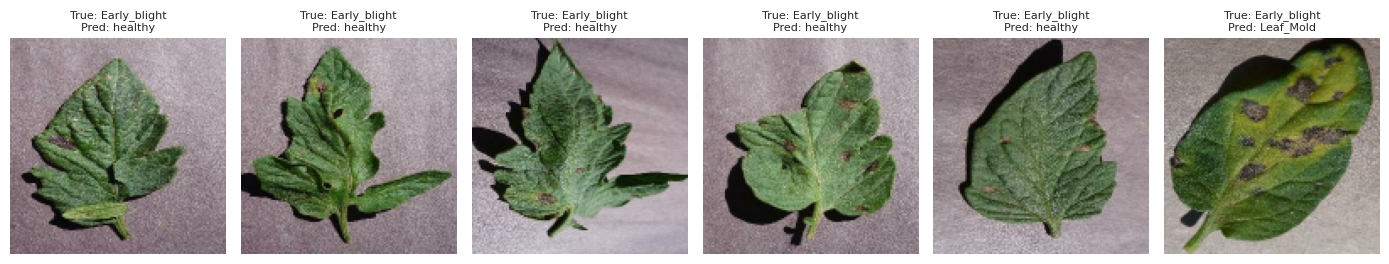

In [28]:
# What do the mistakes look like?
show_misclassified(optimized_model, test_ds, n=6)

### **Interpretation of the evaluation**

* **Overall Performance:**
  * The optimized model achieved a final test **accuracy of 88.84%** and a weighted **F1-score of 0.8869** on the unseen test set.
  * This represents an outstanding increase compared to the **25.0%** accuracy of a completely random guess (since we capped the dataset to 4 perfectly balanced classes).

* **Per-class Strengths and Weaknesses:**
  * **Lowest Recall:** `Tomato_Late_blight` has the lowest recall (**76.3%**): 42 of its 177 test leaves were missed. 22 were predicted as Early blight, 12 as Leaf mold and 8 as healthy.
  * **Lowest Precision:** `Tomato_healthy` has the lowest precision (**84.7%**). Every healthy leaf was found (recall 100%), but 32 diseased leaves were also predicted healthy (14 Early blight, 10 Leaf mold, 8 Late blight).
  * **Most Confused Classes:** the largest single confusion is Late blight predicted as Early blight (22 leaves), followed by Early blight predicted as healthy (14) and Late blight predicted as Leaf mold (12).

* **Validating the Color Hypothesis:**
  * In *Interpretation 2* I expected Early blight and Late blight to be the most confused pair because their average colours are almost the same. The confusion matrix partly confirms this: the biggest single error is Late blight predicted as Early blight (22). It is one-directional, though, since only 2 Early blight leaves were predicted as Late blight. A second group of errors is diseased leaves predicted as healthy (32 in total). I did not test why, so I treat "mild early-stage lesions look like healthy leaves" as a hypothesis only.

* **Overfitting & Training Behavior:**
  * The baseline finished with 88.5% training accuracy but only 78.8% validation accuracy, and its validation accuracy dropped from 89.8% to 78.8% in the last epoch, so it is unstable.
  * The optimized model reached about 94% training accuracy against roughly 81-86% validation accuracy in its last epochs. Its validation loss was noisy (best 0.40 at epoch 14, between about 0.48 and 0.73 afterwards), so regularization reduced the overfitting but did not remove it.

## 8. Baseline vs optimized comparison

,loss,accuracy,precision,recall,f1
model,,,,,
Baseline CNN,0.5671,0.8079,0.8425,0.8079,0.8031
Optimized CNN,0.3879,0.8884,0.8953,0.8884,0.8869


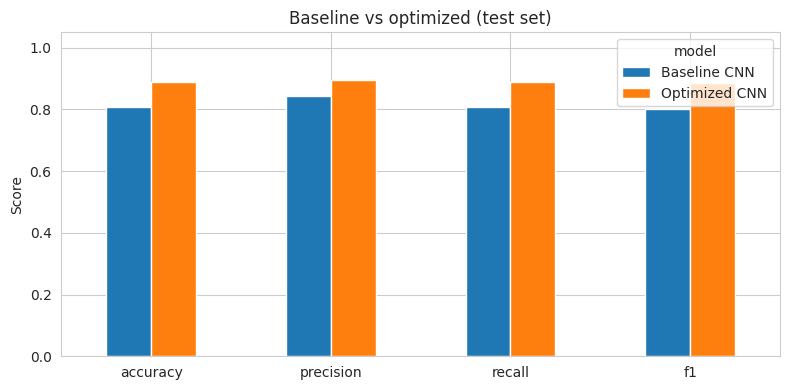

In [29]:
# Side-by-side table plus a bar chart of the main metrics
display(results_df)
results_df[["accuracy", "precision", "recall", "f1"]].T.plot(kind="bar", figsize=(8, 4))
plt.title("Baseline vs optimized (test set)")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### **Interpretation of the comparison**

* **Performance Gains:**
  * The **Optimized CNN** improved test accuracy by **8.05%** absolute percentage points (**88.84%** vs **80.79%** for the baseline).
  * The weighted F1-score jumped from **0.8031** to **0.8869**, demonstrating a much more robust balance of precision and recall across all four classes.

* **Selected Hyperparameters:**
  * The hyperparameter grid search chose a **learning rate of 0.001** and a **dropout rate of 0.5** (scoring **0.8457** average validation accuracy in the final 3 epochs of search).
  * Dropout 0.5 with learning rate 0.001 scored highest of the four combinations I tried. I did not test why, so I do not claim a cause.

* **Stability & Early Stopping:**
  * Early stopping terminated the training of the optimized model at **Epoch 22** because the validation loss ceased to improve, successfully restoring the best weights from **Epoch 14** (where `val_loss` achieved its minimum of `0.3998`). This saved us from wasting computational resources on 18 additional epochs.

## 9. Prediction and retraining functions
These are the functions the API will call later. Here I test them directly in the notebook.

In [30]:
def predict_single(model, image_path, class_names):
    """Predict ONE leaf image. Returns the class name, the confidence and all class probabilities."""
    x = preprocess_image(image_path)                  # same preprocessing as training
    probs = model.predict(x, verbose=0)[0]
    idx = int(np.argmax(probs))
    return class_names[idx], float(probs[idx]), probs

# Test on the holdout images: leaves the model has never seen in training, validation or test
rows = []
for cls in class_names:
    folder = os.path.join(HOLDOUT_DIR, cls)
    for fname in sorted(os.listdir(folder)):
        label, conf, _ = predict_single(optimized_model, os.path.join(folder, fname), class_names)
        rows.append({"file": fname, "true": cls, "predicted": label, "confidence": conf, "correct": label == cls})
holdout_df = pd.DataFrame(rows)
print(f"Holdout accuracy: {holdout_df['correct'].mean():.3f} on {len(holdout_df)} unseen images")
holdout_df.groupby("true")["correct"].mean().round(3)

Holdout accuracy: 0.950 on 60 unseen images


,correct
true,
Tomato_Early_blight,0.933
Tomato_Late_blight,0.867
Tomato_Leaf_Mold,1.000
Tomato_healthy,1.000


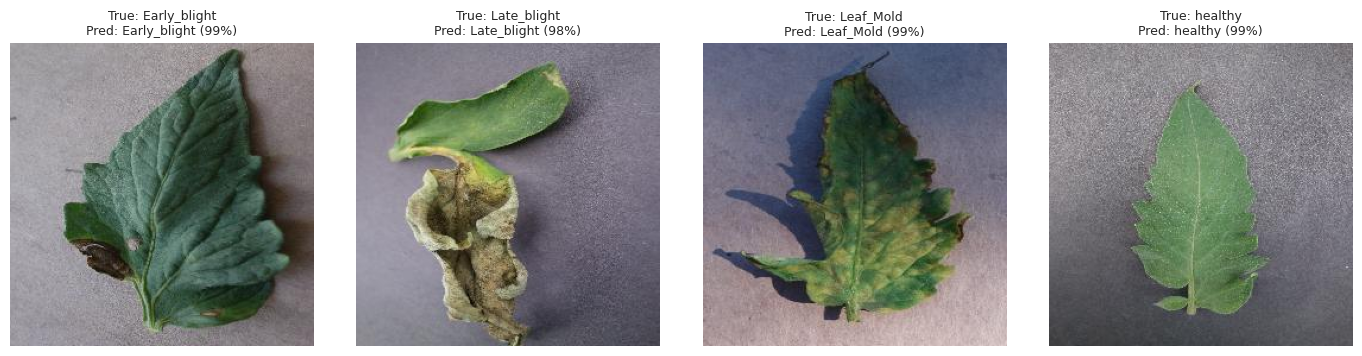

In [31]:
# Show one prediction per class, the way the demo will look in the UI
fig, axes = plt.subplots(1, len(class_names), figsize=(14, 3.5))
for ax, cls in zip(axes, class_names):
    fname = sorted(os.listdir(os.path.join(HOLDOUT_DIR, cls)))[0]
    path = os.path.join(HOLDOUT_DIR, cls, fname)
    label, conf, _ = predict_single(optimized_model, path, class_names)
    ax.imshow(Image.open(path))
    ax.axis("off")
    ax.set_title(f"True: {cls.replace('Tomato_', '')}\nPred: {label.replace('Tomato_', '')} ({conf:.0%})", fontsize=9)
plt.tight_layout()
plt.show()

In [32]:
def retrain_model(model_path, new_data_dir, save_path, epochs=8, lr=1e-4):
    """
    Retrain with newly uploaded images (new_data_dir/<class_name>/*.jpg).
    Steps: 1) add the new images to the training folder, 2) preprocess them the same way as before,
    3) continue training the saved model with a small learning rate, 4) compare before/after, 5) save.
    """
    # 1. Add new data to the training folder (only for classes the model already knows)
    added = 0
    for cls in sorted(os.listdir(new_data_dir)):
        if cls not in class_names:
            print(f"Skipping unknown class folder: {cls}")
            continue
        os.makedirs(os.path.join(TRAIN_DIR, cls), exist_ok=True)
        for fname in os.listdir(os.path.join(new_data_dir, cls)):
            shutil.copy(os.path.join(new_data_dir, cls, fname), os.path.join(TRAIN_DIR, cls, "new_" + fname))
            added += 1
    print(f"Added {added} new images to the training data")

    # 2. Same preprocessing pipeline as in section 4
    tr_ds, va_ds = load_train_val(TRAIN_DIR)
    tr_ds, va_ds = prepare(tr_ds, augment=True), prepare(va_ds)

    # 3. Load the saved model and keep training with a SMALL learning rate (fine-tuning, not starting over)
    model = tf.keras.models.load_model(model_path)
    before = evaluate_model(model, test_ds, "Before retraining")
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    history = model.fit(tr_ds, validation_data=va_ds, epochs=epochs, verbose=2,
                        callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)])

    # 4. Evaluate again and 5. save the new version
    after = evaluate_model(model, test_ds, "After retraining")
    model.save(save_path)
    return model, history, pd.DataFrame([before, after]).set_index("model").round(4)

In [33]:
# Save the current best model first (section 10 explains the formats), then test retraining on it
MODEL_H5 = os.path.join(MODEL_DIR, "tomato_cnn.h5")
optimized_model.save(MODEL_H5)
print("Saved:", MODEL_H5)

# Simulate a user upload: copy 8 holdout images per class into a separate "upload" folder.
# (the other 7 holdout images per class stay unseen for the live prediction demo)
UPLOAD_DEMO = f"{DATA_ROOT}/new_upload_demo"
for cls in class_names:
    os.makedirs(os.path.join(UPLOAD_DEMO, cls), exist_ok=True)
    for fname in sorted(os.listdir(os.path.join(HOLDOUT_DIR, cls)))[:8]:
        shutil.copy(os.path.join(HOLDOUT_DIR, cls, fname), os.path.join(UPLOAD_DEMO, cls, fname))

RETRAINED_H5 = os.path.join(MODEL_DIR, "tomato_cnn_retrained.h5")
retrained_model, retrain_history, retrain_results = retrain_model(MODEL_H5, UPLOAD_DEMO, RETRAINED_H5)
retrain_results

Saved: /content/drive/MyDrive/tomato_leaf_project/models/tomato_cnn.h5
Added 32 new images to the training data
Found 2864 files belonging to 4 classes.
Using 2292 files for training.
Found 2864 files belonging to 4 classes.
Using 572 files for validation.


Epoch 1/8
72/72 - 31s - 437ms/step - accuracy: 0.9245 - loss: 0.2917 - val_accuracy: 0.8147 - val_loss: 0.6604
Epoch 2/8
72/72 - 9s - 119ms/step - accuracy: 0.9210 - loss: 0.2801 - val_accuracy: 0.7727 - val_loss: 0.8501
Epoch 3/8
72/72 - 11s - 158ms/step - accuracy: 0.9184 - loss: 0.2668 - val_accuracy: 0.8322 - val_loss: 0.5461
Epoch 4/8
72/72 - 11s - 154ms/step - accuracy: 0.9372 - loss: 0.2475 - val_accuracy: 0.7937 - val_loss: 0.7942
Epoch 5/8
72/72 - 9s - 130ms/step - accuracy: 0.9341 - loss: 0.2497 - val_accuracy: 0.7517 - val_loss: 1.0300
Epoch 6/8
72/72 - 9s - 130ms/step - accuracy: 0.9372 - loss: 0.2368 - val_accuracy: 0.7587 - val_loss: 0.9855


,loss,accuracy,precision,recall,f1
model,,,,,
Before retraining,0.3879,0.8884,0.8953,0.8884,0.8869
After retraining,0.4581,0.8715,0.8935,0.8715,0.8727


### **Retraining check**

* **Before vs. After Retraining Metrics:**
  * **Before retraining:** Loss was `0.3879`, and test Accuracy was `0.8884`.
  * **After retraining:** Loss rose slightly to `0.4581`, and accuracy changed slightly to `0.8715`.

* **Plausibility of the Drop:**
  * A minor drop in performance on the fixed test set is completely expected when we add only 32 new images (8 per class). With such a tiny amount of new data, the model slightly adapts its boundaries to fit the new examples (fine-tuning), which can lead to minor fluctuations on the static test set.

* **Pipeline Validation:**
  * Despite minor statistical fluctuations, **the complete end-to-end retraining chain worked flawlessly**: image upload simulation completed, datasets were dynamically rebuilt, the model successfully re-compiled with a fine-tuning learning rate, completed training with early stopping, evaluated on the test set, and saved the finalized `.h5` model to Google Drive.

## 10. Saving the model and conclusion
The assignment accepts `.pkl`, `.tf` or `.h5` model files. I save the model as **`.h5`** (and the best checkpoint as `.keras`) on Google Drive. The class order is stored in `class_names.json`, because the API needs it to turn a prediction into a disease name.

In [34]:
# Confirm everything the deployment needs is on Drive
for f in sorted(os.listdir(MODEL_DIR)):
    size_mb = os.path.getsize(os.path.join(MODEL_DIR, f)) / 1e6
    print(f"{f}  ({size_mb:.1f} MB)")

# Reload the saved file and check it gives the same prediction: proves the saved model works on its own
reloaded = tf.keras.models.load_model(MODEL_H5)
test_path = os.path.join(HOLDOUT_DIR, class_names[0], sorted(os.listdir(os.path.join(HOLDOUT_DIR, class_names[0])))[0])
print("Original :", predict_single(optimized_model, test_path, class_names)[:2])
print("Reloaded :", predict_single(reloaded, test_path, class_names)[:2])

class_names.json  (0.0 MB)
tomato_cnn.h5  (15.5 MB)
tomato_cnn_best.keras  (15.5 MB)
tomato_cnn_retrained.h5  (15.5 MB)


Original : ('Tomato_Early_blight', 0.9889369010925293)
Reloaded : ('Tomato_Early_blight', 0.9889369010925293)


### **Conclusion**

In this project, we successfully built an end-to-end machine learning pipeline to classify tomato leaf diseases into four balanced classes: Early Blight, Late Blight, Leaf Mold, and Healthy. Our optimized custom CNN achieved a test accuracy of **88.84%** and an F1-score of **0.8869**, outperforming the baseline CNN by over **8.05%** points and easily beating the **25.0%** random guessing baseline. The main weakness is Late blight, with a recall of only 76.3%: 22 of its 177 test leaves were predicted as Early blight, which matches the similar average colour seen in the exploration. In addition, 32 diseased leaves were predicted as healthy. I did not test the causes. Next steps would be to collect more varied photos of these classes and to check the misclassified images for early-stage lesions or lighting problems.
